# Comparing boxcar and Tukey windows

This notebook contains a minimal comparison between the default boxcar Fresnel kernel and the Tukey-windowed Fresnel kernel (`use_tukey=True`).

In [8]:
import matplotlib.pyplot as plt
import numpy as np

from pygwtf.generator import AnalyticTimeFrequencyWaveform
from pygwtf.models import TaylorT3Spin

In [9]:
dT = 86400 / 4  # 6 hours
nT = 365 * 4  # 1 year
dt = 5
dF = 1 / dT
fmax = 1 / (2 * dt) # Nyquist frequency for the time-domain data

nF = int((fmax)/ dF) + 1 # Number of frequency bins needed to cover the Nyquist frequency.

config = {
    "dT": dT,
    "nT": nT,
    "dt": dt,
    "dF": dF,
    "nF": nF,
    "kernel_width": 10,  # number of frequency bins to use in the fresnel kernel
}

The Tukey kernel needs the taper parameter `alpha` in the config (it should match the window applied to the data), and is midpoint only.

In [10]:
boxcar_generator = AnalyticTimeFrequencyWaveform(
    model_class=TaylorT3Spin,
    config=config.copy(),
    tdi_type=None,
)

tukey_generator = AnalyticTimeFrequencyWaveform(
    model_class=TaylorT3Spin,
    config={**config, "alpha": 0.1},  # Tukey taper parameter
    tdi_type=None,
    use_tukey=True,
)

Spacecraft light travel times not supplied. Falling back to analytic calculation
Spacecraft light travel times not supplied. Falling back to analytic calculation


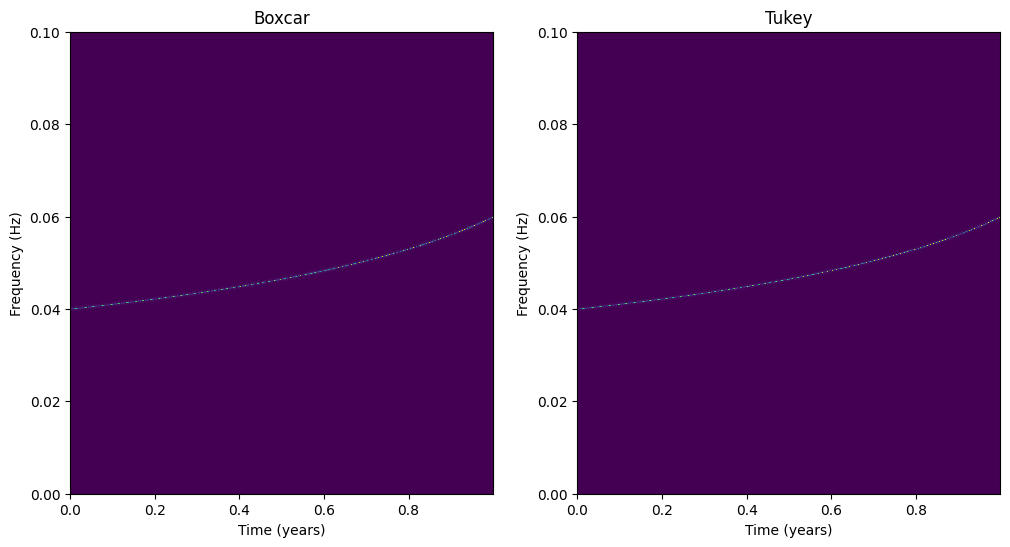

In [11]:
pars = {
    "M": 30,
    "eta": 0.25,
    "cosi": 0.5,
    "D": 1e3,
    "f0": 4e-2,
    "phi_coal": 0.1,
    "s1": 0.3,
    "s2": -0.2,
}

tf_boxcar = boxcar_generator(pars)
tf_tukey = tukey_generator(pars)

plt.figure(figsize=(12, 6))
plt.subplot(121)
plt.pcolormesh(
    boxcar_generator.t_tranche/(365.25*24*3600), boxcar_generator.f_tranche, np.abs(tf_boxcar[:, :, 0].T)
)
plt.title("Boxcar")
plt.xlabel("Time (years)")
plt.ylabel("Frequency (Hz)")
plt.subplot(122)
plt.pcolormesh(
    tukey_generator.t_tranche/(365.25*24*3600), tukey_generator.f_tranche, np.abs(tf_tukey[:, :, 0].T)
)
plt.title("Tukey")
plt.xlabel("Time (years)")
plt.ylabel("Frequency (Hz)")
plt.show()

A single segment, zoomed around the signal:

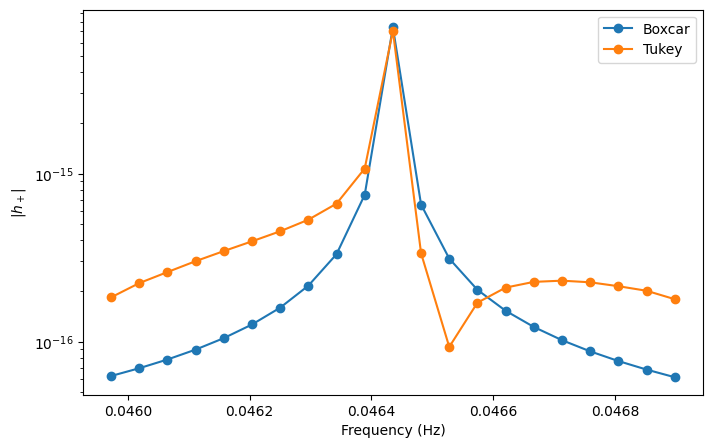

In [12]:
i = nT // 2
k = np.argmax(np.abs(tf_boxcar[i, :, 0]))
sl = slice(k - config["kernel_width"], k + config["kernel_width"] + 1)

plt.figure(figsize=(8, 5))
plt.semilogy(boxcar_generator.f_tranche[sl], np.abs(tf_boxcar[i, sl, 0]), "o-", label="Boxcar")
plt.semilogy(tukey_generator.f_tranche[sl], np.abs(tf_tukey[i, sl, 0]), "o-", label="Tukey")
plt.xlabel("Frequency (Hz)")
plt.ylabel(r"$|h_+|$")
plt.legend()
plt.show()

Mismatch between the two waveforms, assuming a flat PSD:

In [13]:
mismatch = (
    1
    - np.abs((tf_boxcar.conj() * tf_tukey).sum())
    / (tf_boxcar.conj() * tf_boxcar).real.sum() ** 0.5
    / (tf_tukey.conj() * tf_tukey).real.sum() ** 0.5
)

print(f"Mismatch between boxcar and Tukey: {mismatch:.2e}")

Mismatch between boxcar and Tukey: 1.15e-02
